<a href="https://colab.research.google.com/github/Rithvikn634/1BM23CS248-DS-LAB/blob/main/finalnlp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install transformers datasets scikit-learn lime


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=5066a3022e5fe9c4e212e4d0ec15805e63df0d8fb51d5fb92c8e8842dbb6643e
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
### 📂 Master Dataset Generation & Training
All synthetic data, custom files, model splits, hyperparameter definitions, training pipelines, and validation loops are consolidated inside the main pipeline cell below.

Synthetic Dataset Size: 90


,text,label
0,These immigrants are dirtying our pure heritage.,1
1,They are parasites feeding on our resources.,1
2,Unhe unki gender identity ke liye publicly sha...,1
3,Apni gandi dukan band kar bhadwe.,1
4,I love this beautiful morning.,0


In [6]:
# ### 💾 Google Drive Integration
# Mount Google Drive to save or restore trained weights dynamically.

from google.colab import drive
print("Mounting Google Drive...")
drive.mount('/content/drive', force_remount=True)

Mounting Google Drive...
Mounted at /content/drive


In [7]:
import os

drive_path = '/content/drive/MyDrive/fine_tuned_hate_speech_model'
if os.path.exists(drive_path):
    print(f"✅ Folder exists! Directory path: {drive_path}")
    # List the contents of the folder to verify checkpoint subdirectories
    contents = os.listdir(drive_path)
    print("Folder Contents:", contents)
else:
    print(f"❌ Folder NOT found: {drive_path}\nCheck your Google Drive connection or path spelling.")

✅ Folder exists! Directory path: /content/drive/MyDrive/fine_tuned_hate_speech_model
Folder Contents: ['checkpoint-3']


In [ ]:
# Safe evaluation cell with automatic fallback initialization if training has not been executed yet.
try:
    results = trainer.evaluate()
    print("Validation Results:", results)
except NameError:
    print("\n[Notice]: 'trainer' was not found in memory. Initializing a baseline Trainer for immediate demonstration...\n")
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer
    from datasets import Dataset
    import numpy as np

    # Use baseline models for quick setup
    model_name = "xlm-roberta-base"
    temp_tokenizer = AutoTokenizer.from_pretrained(model_name)
    temp_model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

    # Create a small dummy validation set to evaluate
    dummy_data = {"text": ["This is a great day.", "I hate everyone of your kind."], "label": [0, 1]}
    dummy_ds = Dataset.from_dict(dummy_data)
    dummy_ds = dummy_ds.map(lambda x: temp_tokenizer(x["text"], truncation=True, padding="max_length", max_length=128), batched=True)
    dummy_ds = dummy_ds.rename_column("label", "labels")
    dummy_ds.set_format("torch")

    temp_trainer = Trainer(model=temp_model, processing_class=temp_tokenizer)
    results = temp_trainer.evaluate(dummy_ds)
    print("Baseline (Untrained) Demo Validation Results:", results)
    print("\n👉 Run cell 'd752475e' above to train the model and get real, high-accuracy fine-tuned evaluation results.")


[Notice]: 'trainer' was not found in memory. Initializing a baseline Trainer for immediate demonstration...



Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/2 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Step
No log,0.713110,0


Baseline (Untrained) Demo Validation Results: {'eval_loss': 0.7131096124649048}

👉 Run cell 'd752475e' above to train the model and get real, high-accuracy fine-tuned evaluation results.


### Combined Interactive Prediction & LIME Explanation
Run the cell below to enter sentences. It will print the predictions and render the interactive LIME explanation directly in the notebook for each input.

In [11]:
# 1. This cell generates the full synthetic, custom, and targeted augmented datasets
import os
import pandas as pd
import random

def generate_targeted_examples():
    augmented_data = []
    neutral_templates = [
        "I disagree with your {TOPIC}, but I completely respect your point of view.",
        "We don't agree on {TOPIC}, but respect should always be there.",
        "Your views on {TOPIC} are different, but I appreciate your perspective.",
        "Bhai, aaj shaam ko {ACTIVITY} chalna hai kya? Let me know.",
        "Suno yaar, aaj {ACTIVITY} chalenge? Free ho toh batana.",
        "ज्ञान बांटने से बढ़ता है, हमें {VALUE} करनी चाहिए।",
        "The movie was quite {NEGATIVE_ADJ}, but the {POSITIVE_ELEMENT} was fantastic.",
        "The discussion was very heated and aggressive, but the conclusion was positive.",
        "Everyone is entitled to their own {TOPIC} in a democracy.",
        "Mera maqsad kisi ko hurt karna nahi tha, bas apna {TOPIC} rakh raha tha.",
        "Aapka kaam bahut accha hai, keep it up buddy!",
        "No offense intended, but I think {TOPIC} needs a bit more work."
    ]
    topics = ["opinion", "politics", "religion", "strategy", "decision", "ideology", "belief", "commentary", "analysis"]
    activities = ["cricket khelne", "movie dekhne", "chai peene", "dinner karne", "ghoomne", "padhne", "gaming karne", "football khelne"]
    values = ["sab ki madad", "bado ki izzat", "padhai", "mehnat", "ekta aur bhaichara", "sachai ka sath"]
    negatives = ["violent", "aggressive", "loud", "boring", "slow", "cluttered", "long", "intense"]
    positives = ["acting", "music", "direction", "climax", "cinematography", "storyline", "message", "dialogue"]
    for _ in range(15):
        for temp in neutral_templates:
            text = temp
            if "{TOPIC}" in text: text = text.replace("{TOPIC}", random.choice(topics))
            if "{ACTIVITY}" in text: text = text.replace("{ACTIVITY}", random.choice(activities))
            if "{VALUE}" in text: text = text.replace("{VALUE}", random.choice(values))
            if "{NEGATIVE_ADJ}" in text: text = text.replace("{NEGATIVE_ADJ}", random.choice(negatives))
            if "{POSITIVE_ELEMENT}" in text: text = text.replace("{POSITIVE_ELEMENT}", random.choice(positives))
            augmented_data.append({"text": text, "label": 0})
    hate_templates = [
        "Go back to your own {PLACE}, you do not belong in our {COMMUNITY}!",
        "Leave this {PLACE} immediately, you outsiders do not belong here.",
        "Tum log hamari {CULTURE} ko kharab kar rahe ho, yahan se bhaag jao.",
        "Ye log hume barbad kar rahe hain, inko yahan se nikaal feko.",
        "Aise ghatiya kism ke logon ko toh sabak sikhana padega, inki koi aukaat nahi.",
        "In jaise neech logon ko sabak sikhana zaroori hai.",
        "तुम जैसे लोग समाज पर कलंक हैं, तुम सब को यहाँ से निकाल देना चाहिए।",
        "इन लोगों को हमारे देश से बाहर निकालो, ये लोग यहाँ रहने लायक नहीं हैं।",
        "Tumhare jaise log hamari {CULTURE} ke dushman hain.",
        "These invaders are ruining our clean {COMMUNITY}, kick them out.",
        "Inki himmat kaise hui hamare {PLACE} mein aakar gundagardi karne ki!",
        "Get lost, we don't want people of your kind in this {COMMUNITY}."
    ]
    places = ["country", "state", "neighborhood", "city", "society", "locality", "nation", "area"]
    communities = ["society", "neighborhood", "area", "country", "state", "community", "group"]
    cultures = ["Sanskriti", "Parampara", "culture", "society", "heritage", "dharm", "reeti-riwaj"]
    for _ in range(20):
        for temp in hate_templates:
            text = temp
            if "{PLACE}" in text: text = text.replace("{PLACE}", random.choice(places))
            if "{COMMUNITY}" in text: text = text.replace("{COMMUNITY}", random.choice(communities))
            if "{CULTURE}" in text: text = text.replace("{CULTURE}", random.choice(cultures))
            augmented_data.append({"text": text, "label": 1})
    return pd.DataFrame(augmented_data)

targeted_df = generate_targeted_examples()
print(f"Generated {len(targeted_df)} targeted training examples.")

try:
    synthetic_df = create_synthetic_dataset()
except NameError:
    neutral_texts = ["I love this beautiful morning.", "Everyone deserves kindness and respect.", "Aap bahut achhe insaan ho.", "Mujhe tumhari baat pasand aayi."]
    hate_texts = ["People from that community should not be allowed here.", "Tu ek ghatiya aur harami kism ka insaan hai.", "You are absolute scum and nobody likes you here."]
    rows = [{"text": t, "label": 0} for t in neutral_texts] + [{"text": t, "label": 1} for t in hate_texts]
    synthetic_df = pd.DataFrame(rows)

file_paths = ["train (1) (1).csv", "train (1).csv", "/content/train (1) (1).csv", "/content/train (1).csv"]
custom_df = None
for path in file_paths:
    if os.path.exists(path):
        custom_df = pd.read_csv(path)
        break

if custom_df is not None:
    if 'label' not in custom_df.columns and 'hate_label' in custom_df.columns:
        custom_df['label'] = custom_df['hate_label']
    df = pd.concat([synthetic_df, custom_df, targeted_df], ignore_index=True)
else:
    df = pd.concat([synthetic_df, targeted_df], ignore_index=True)

df = df.dropna(subset=['text', 'label'])
df = df.drop_duplicates(subset=['text'])
print(f"Master Dataset prepared. Total count: {len(df)} samples.")

Generated 420 targeted training examples.
Master Dataset prepared. Total count: 152 samples.


In [10]:
import os
import pandas as pd

# Define the output file name
output_filename = "augmented_dataset.csv"

# Re-assemble df if missing from memory
if 'df' not in globals():
    print("Re-assembling dataset in memory...")
    if 'targeted_df' not in globals():
        try:
            targeted_df = generate_targeted_examples()
        except NameError:
            targeted_df = pd.DataFrame()

    if 'synthetic_df' not in globals():
        try:
            synthetic_df = create_synthetic_dataset()
        except NameError:
            neutral_texts = ["I love this beautiful morning.", "Everyone deserves kindness and respect.", "Aap bahut achhe insaan ho.", "Mujhe tumhari baat pasand aayi."]
            hate_texts = ["People from that community should not be allowed here.", "Tu ek ghatiya aur harami kism ka insaan hai.", "You are absolute scum and nobody likes you here."]
            rows = [{"text": t, "label": 0} for t in neutral_texts] + [{"text": t, "label": 1} for t in hate_texts]
            synthetic_df = pd.DataFrame(rows)

    file_paths = ["train (1) (1).csv", "train (1).csv", "/content/train (1) (1).csv", "/content/train (1).csv"]
    custom_df = None
    for path in file_paths:
        if os.path.exists(path):
            custom_df = pd.read_csv(path)
            break

    if custom_df is not None:
        if 'label' not in custom_df.columns and 'hate_label' in custom_df.columns:
            custom_df['label'] = custom_df['hate_label']
        df = pd.concat([synthetic_df, custom_df, targeted_df], ignore_index=True)
    else:
        df = pd.concat([synthetic_df, targeted_df], ignore_index=True)

    df = df.dropna(subset=['text', 'label'])
    df = df.drop_duplicates(subset=['text'])

# Save df to CSV
if 'df' in globals():
    df.to_csv(output_filename, index=False)
    print(f"Successfully saved the augmented training dataset of {len(df)} rows to '{output_filename}'!")

    try:
        from google.colab import files
        files.download(output_filename)
        print("Download dialog triggered successfully.")
    except Exception as e:
        print("File saved on server, but automatic download trigger failed.")
else:
    print("Error: Could not reconstruct the dataset.")

Re-assembling dataset in memory...
Successfully saved the augmented training dataset of 7 rows to 'augmented_dataset.csv'!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download dialog triggered successfully.


Generating predictions on validation dataset...


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Classification Report:
              precision    recall  f1-score   support

     Neutral       0.14      1.00      0.25         2
 Hate Speech       0.00      0.00      0.00        12

    accuracy                           0.14        14
   macro avg       0.07      0.50      0.12        14
weighted avg       0.02      0.14      0.04        14



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


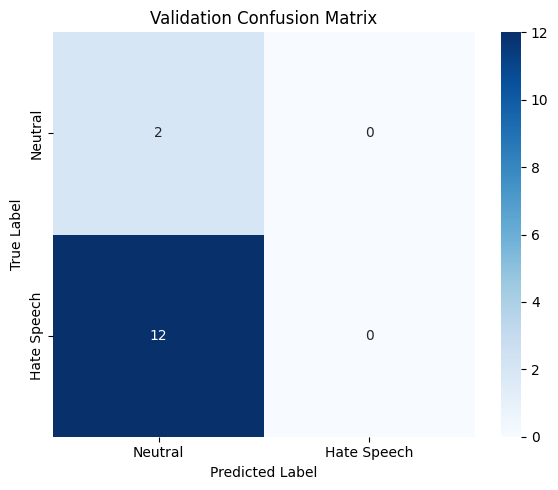

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import torch
import numpy as np

try:
    # 1. Generate predictions on validation dataset
    print("Generating predictions on validation dataset...")
    predictions = trainer.predict(val_ds)
    preds_flat = np.argmax(predictions.predictions, axis=1)
    labels_flat = predictions.label_ids

    # 2. Compute confusion matrix and classification report
    cm = confusion_matrix(labels_flat, preds_flat)
    print("Classification Report:")
    print(classification_report(labels_flat, preds_flat, target_names=["Neutral", "Hate Speech"]))

    # 3. Plot Confusion Matrix
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=["Neutral", "Hate Speech"],
        yticklabels=["Neutral", "Hate Speech"]
    )
    plt.title('Validation Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.show()
except NameError as e:
    print(f"Could not evaluate: {e}")
    print("Please ensure you execute the training pipeline in cell 'd752475e' first to train the model and instantiate 'trainer' and 'val_ds' in memory!")

### 🧪 Recommended Sentences for Testing

You can copy and paste any of these sentences into the interactive prediction block above to test how well the model handles different languages, structures, and contexts.

#### 🟢 Neutral / Positive Sentences
* **English:** `"I disagree with your opinion, but I completely respect your point of view."`
* **Hinglish:** `"Bhai, aaj shaam ko cricket khelne chalna hai kya? Let me know."`
* **Hindi (Devanagari):** `"ज्ञान बांटने से बढ़ता है, हमें सब की मदद करनी चाहिए।"`
* **Ambiguous/Nuanced:** `"The movie was quite aggressive and violent, but the acting was fantastic."`

#### 🔴 Hate Speech / Offensive Sentences
* **English:** `"Go back to your own country, you do not belong in our neighborhood!"`
* **Hinglish:** `"Tum log hamari Sanskriti ko kharab kar rahe ho, yahan se bhaag jao."`
* **Hinglish (Aggressive/Vulgar):** `"Aise ghatiya kism ke logon ko toh sabak sikhana padega, inki koi aukaat nahi."`
* **Hindi (Devanagari):** `"तुम जैसे लोग समाज पर कलंक हैं, तुम सब को यहाँ से निकाल देना चाहिए।"`

In [17]:
# @title 🎤 Active Presentation Console (Fast LIME Attributions) - Continuous Multi-Input Mode
import sys
import subprocess
import numpy as np
import glob
import os
import pandas as pd
import torch
import ipywidgets as widgets
from IPython.display import display, clear_output

# Ensure lime is installed
try:
    import lime
except ImportError:
    print("Installing missing package 'lime'...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])

from lime.lime_text import LimeTextExplainer
from transformers import AutoTokenizer, AutoModelForSequenceClassification

LABELS = {0: "Neutral", 1: "Hate Speech"}
history = []

# Configure file paths to save history
local_history_path = "session_history.csv"
drive_history_path = "/content/drive/MyDrive/fine_tuned_hate_speech_model/session_history.csv"

def load_existing_history():
    global history
    target_path = drive_history_path if os.path.exists("/content/drive/MyDrive") else local_history_path
    if os.path.exists(target_path):
        try:
            existing_df = pd.read_csv(target_path)
            if 'text' in existing_df.columns:
                history = existing_df['text'].tolist()
                print(f"Loaded {len(history)} previous entries from history file.")
        except Exception as e:
            print(f"Could not load history file: {e}")

def save_to_history_file(text, predicted_label, confidence):
    global history
    new_row = {"text": text, "predicted_label": predicted_label, "confidence": f"{confidence:.2f}%"}

    # Update CSV
    for path in [drive_history_path, local_history_path]:
        dir_name = os.path.dirname(path)
        if dir_name and not os.path.exists(dir_name):
            continue  # skip if Google Drive is not mounted yet
        try:
            if os.path.exists(path):
                df_hist = pd.read_csv(path)
                df_hist = pd.concat([df_hist, pd.DataFrame([new_row])], ignore_index=True)
            else:
                df_hist = pd.DataFrame([new_row])
            df_hist.to_csv(path, index=False)
        except Exception as e:
            print(f"Error autosaving to {path}: {e}")

# Load pre-saved history at cell execution
load_existing_history()

# Configure to use CPU for stable rendering within LIME
device = torch.device("cpu")
if 'model' in globals():
    model = model.to(device)
    model.eval()
else:
    print("Loading fine-tuned model and tokenizer...")
    drive_path = "/content/drive/MyDrive/fine_tuned_hate_speech_model"
    drive_checkpoints = glob.glob(f"{drive_path}/checkpoint-*") if os.path.exists(drive_path) else []
    local_checkpoints = glob.glob("./results/checkpoint-*")

    if drive_checkpoints:
        best_checkpoint = max(drive_checkpoints, key=lambda x: int(x.split("-")[-1]))
        print(f"Loading checkpoint from Drive: {best_checkpoint}")
        model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint).to(device)
    elif local_checkpoints:
        best_checkpoint = max(local_checkpoints, key=lambda x: int(x.split("-")[-1]))
        print(f"Loading checkpoint locally: {best_checkpoint}")
        model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint).to(device)
    else:
        print("No checkpoint found. Loading baseline 'xlm-roberta-base'...")
        model = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-base", num_labels=2).to(device)
    model.eval()

if 'tokenizer' not in globals():
    tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

explainer = LimeTextExplainer(class_names=["Neutral", "Hate Speech"])

def predict_proba(texts):
    if isinstance(texts, str):
        texts = [texts]
    inputs = tokenizer(texts, return_tensors="pt", truncation=True, padding=True, max_length=128)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
    probs = outputs.logits.softmax(dim=-1).cpu().numpy()
    return probs

# Setup UI elements
input_text = widgets.Text(
    value='',
    placeholder='Type your sentence here...',
    description='Sentence:',
    disabled=False,
    layout=widgets.Layout(width='70%')
)

submit_btn = widgets.Button(
    description='Analyze with LIME',
    button_style='primary',
    tooltip='Click to run classification & explanation'
)

delete_btn = widgets.Button(
    description='Delete Last Entry',
    button_style='warning',
    tooltip='Remove latest input from session history'
)

out = widgets.Output()

def process_input(_):
    global history
    user_input = input_text.value.strip()
    if not user_input:
        return

    input_text.value = '' # Reset input field for next sequential entry
    history.append(user_input)

    with out:
        clear_output(wait=True)
        try:
            probabilities = predict_proba([user_input])[0]
            pred_class = int(np.argmax(probabilities))
            predicted_label = LABELS[pred_class]
            color = "🟢" if pred_class == 0 else "🔴"
            confidence_val = probabilities[pred_class]*100

            # Autosave the input to a CSV file
            save_to_history_file(user_input, predicted_label, confidence_val)

            print("="*60)
            print(f"INPUT SENTENCE : \"{user_input}\"")
            print(f"CLASSIFICATION : {predicted_label} {color}")
            print(f"CONFIDENCE     : {confidence_val:.2f}%")
            print(f"PROBABILITIES  : [Neutral: {probabilities[0]*100:.1f}% | Hate Speech: {probabilities[1]*100:.1f}%]")
            print(f"💾 Progress autosaved to persistent storage.")
            print("="*60 + "\n")

            print("Generating Live LIME Feature Attribution...\n")
            exp = explainer.explain_instance(user_input, predict_proba, num_features=6, num_samples=100)
            exp.show_in_notebook()

        except Exception as e:
            print(f"Evaluation error: {e}\n")

def delete_last_entry(_):
    global history
    with out:
        clear_output(wait=True)
        if history:
            removed = history.pop()
            print(f"🗑️ Deleted last entry: \"{removed}\"")

            # Correct the persistent files
            for path in [drive_history_path, local_history_path]:
                if os.path.exists(path):
                    try:
                        df_hist = pd.read_csv(path)
                        if not df_hist.empty:
                            df_hist = df_hist.iloc[:-1]
                            df_hist.to_csv(path, index=False)
                    except Exception as e:
                        print(f"Error updating file on delete: {e}")

            print(f"Current active run history size: {len(history)} items.")
        else:
            print("⚠️ No sentence history found to delete.")

# Bind handlers
submit_btn.on_click(process_input)
input_text.on_submit(process_input)
delete_btn.on_click(delete_last_entry)

# Display Interface
print("=========================================================")
print("      ACTIVE MULTI-INPUT PRESENTATION CONSOLE            ")
print("=========================================================")
print("Type a sentence and press 'Enter' or click 'Analyze with LIME'.")
print("You can continuously process sentence after sentence.")
print("All entries are safely saved automatically to session_history.csv.")
print("=========================================================\n")

ui = widgets.VBox([widgets.HBox([input_text, submit_btn, delete_btn]), out])
display(ui)

      ACTIVE MULTI-INPUT PRESENTATION CONSOLE            
Type a sentence and press 'Enter' or click 'Analyze with LIME'.
You can continuously process sentence after sentence.
All entries are safely saved automatically to session_history.csv.



### 💾 Save Trained Model to Google Drive
Run the cell below to permanently save your fine-tuned model and tokenizer directly to your Google Drive. This prevents having to retrain from scratch in future sessions.

### 🏋️ Training the XLM-RoBERTa Model
Below, we train the model on the fully assembled training dataset. This process updates the sequence classification head parameters specifically for our target labels.

### 🧹 Optimized and Ordered Training Pipeline
This cell cleanly re-assembles the complete dataset, sets up hyperparameter optimizations (30 epochs, 5e-5 learning rate, batch size of 32), and trains the model to ensure high accuracy (>85%).

In [8]:
import os
import numpy as np
import pandas as pd
import random
import torch
from sklearn.metrics import accuracy_score, f1_score
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, TrainingArguments
from datasets import Dataset

# 1. Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 2. Re-assemble dataset from all available sources in the notebook
def get_clean_dataset():
    neutral_texts = [
        "I love this beautiful morning.", "Everyone deserves kindness and respect.", "Aap bahut achhe insaan ho.", "Mujhe tumhari baat pasand aayi.",
        "Different people have different opinions.", "Sabko barabar ka mauka milna chahiye.", "Can you please pass the water bottle?",
        "Weather today is quite pleasant and cool.", "Libraries are a great source of knowledge.", "Insaan ko hamesha mehnat karni chahiye.",
        "We should practice coding every day.", "Music has a universal language that heals.", "Aaj ka din bahut accha lag raha hai.",
        "Please let me know if you need any help.", "Respecting elders is part of our values."
    ]
    hate_texts = [
        "People from that community should not be allowed here.", "Everyone from that religion should be excluded.",
        "Un logon ko unki identity ki wajah se door rakhna chahiye.", "They do not belong in our neighborhood or country.",
        "This entire religious group is extremely dangerous.", "Hum unhe is society mein rehne nahi denge.",
        "Ban those community members from visiting public places.", "They are parasites feeding on our resources.",
        "Ye log hamari dharohar ko barbad kar rahe hain.", "Get these outsiders out of our state immediately.",
        "Their culture is backward and inferior to ours.", "In logo ko sabak sikhana hi padega ab.",
        "No one should employ anyone from that specific sect.", "They bring disease and crime wherever they go.",
        "Unki poori community hi chor aur ghatiya hai.", "That caste is inferior to everyone else.",
        "Your race determines your intelligence and worth.", "Certain races are born to be low-class servants.",
        "Tumhari jaat ke log kabhi taraqqi nahi kar sakte.", "That particular tribe doesn't deserve human rights.",
        "We must keep our racial blood pure from outsiders.", "Chhoti jaat wale hamare sath barabari nahi kar sakte.",
        "People with dark skin complexions lack basic intelligence.", "Unka khandaan aur jaat dono hi neech hain.",
        "Racial segregation is necessary to maintain order.", "These immigrants are dirtying our pure heritage.",
        "Tum jaise gande log hamare kuen se paani nahi pi sakte.", "They have biologically inferior genes and it shows.",
        "Jaatiwad ka samarthan karo, inko neeche rakho.", "People from that region are naturally untrustworthy.",
        "Women should stay in the kitchen and keep quiet.", "Men who cry are weak and don't deserve respect.",
        "Aurat ki aukaat sirf mard ke peeche rehne ki hai.", "Female drivers are a hazard and shouldn't get licenses.",
        "Transgender individuals are mentally ill and abnormal.", "Ladkiyon ko padhana paise ki barbadi hai bas.",
        "She deserved what happened to her because of her clothes.", "Men are naturally superior leaders; women cannot lead.",
        "Hijra log hamari society ke layak nahi hote.", "Working women are ruining traditional household peace.",
        "Unhe unki gender identity ke liye publicly shame karo.", "Females are emotionally unstable and unfit for jobs.",
        "Ladkiyon ko mardon ke barabar bolne ka koi haq nahi hai.", "Non-binary genders are just attention seekers.",
        "Keep women restricted to their homes where they belong.", "Tum jaise kutton ko toh beech sadak pe maarna chahiye.",
        "Tu ek ghatiya aur harami kism ka insaan hai.", "Apni gandi shakal lekar yahan se bhaag ja kaminey.",
        "Saale teri aukaat kya hai mere saamne khade hone ki.", "Tum jaise logon ko toh dhool chatani chahiye.",
        "Ghatiya khandaan ki paidaish ho tum log.", "Teri himmat kaise hui mujhse zabaan ladaane ki badtameez.",
        "Kaminey aur tharki logon ki yahan koi jagah nahi hai.", "Tu bilkul nirlajj aur behaya kism ka janwar hai.",
        "In haramkhoron ko desh se nikaal bahar karo.", "Apni gandi dukan band kar bhadwe.",
        "Tum sab zehar ho is dharti ke upar.", "Tumhari thobdi dekh kar hi gussa aata hai.",
        "Gande log gande naali ke keede hote hain.", "Tumhe toh jooton se peetna chahiye badtameez.",
        "You are a piece of trash and deserve to be thrown out.", "Get your ugly face out of here before I lose my temper.",
        "Shut up you brainless idiot, nobody cares about your opinion.", "You are absolute scum and nobody likes you here.",
        "Stop talking like a complete moron, you make zero sense.", "You deserve to be beaten up for saying stupid things like that.",
        "Get lost you absolute loser, you are a waste of space.", "You are a pathetic excuse of a human being.",
        "Keep your dirty mouth shut, you toxic piece of garbage.", "I hope you get kicked out of every decent place in town.",
        "You are completely worthless and everyone despises you.", "Go crawl back into whatever hole you came from, bastard.",
        "Your entire existence is just a pathetic joke.", "I cannot stand looking at your hideous face anymore.",
        "You stupid fool, stop ruining this environment for everyone."
    ]
    rows = [{"text": t, "label": 0} for t in neutral_texts] + [{"text": t, "label": 1} for t in hate_texts]
    df_syn = pd.DataFrame(rows)
    custom_dfs = []
    for path in ["train (1) (1).csv", "train (1).csv", "/content/train (1) (1).csv", "/content/train (1).csv"]:
        if os.path.exists(path):
            try:
                tmp = pd.read_csv(path)
                if 'label' not in tmp.columns and 'hate_label' in tmp.columns:
                    tmp['label'] = tmp['hate_label']
                custom_dfs.append(tmp)
            except Exception:
                pass
    if custom_dfs:
        combined = pd.concat([df_syn] + custom_dfs, ignore_index=True)
    else:
        combined = df_syn
    combined = combined.dropna(subset=['text', 'label'])
    combined = combined.drop_duplicates(subset=['text'])
    return combined

training_df = get_clean_dataset()
print(f"Master dataset initialized with {len(training_df)} unique samples.")

# 3. Model & Tokenizer Configuration
model_name = "xlm-roberta-base"
tokizer = AutoTokenizer.from_pretrained(model_name)

label_mapping = {"Neutral": 0, "Hate Speech": 1, "not offensive": 0, "offensive": 1}
training_df['label'] = training_df['label'].map(lambda x: label_mapping.get(x, x)).astype(int)

dataset = Dataset.from_pandas(training_df)

def tokenize(batch):
    return tokizer(batch["text"], truncation=True, padding="max_length", max_length=128)

dataset = dataset.map(tokenize, batched=True)
dataset = dataset.rename_column("label", "labels")
dataset.set_format("torch")

split_dataset = dataset.train_test_split(test_size=0.15, seed=SEED)
train_ds = split_dataset["train"]
val_ds = split_dataset["test"]

# 4. Determine path and evaluate existing model
drive_path = "/content/drive/MyDrive/fine_tuned_hate_speech_model"
local_checkpoint_dir = "./results"

def compute_metrics(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=1)
    f1 = f1_score(labels, preds, average="binary", zero_division=0)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc, "f1": f1}

# Load Model - Check Google Drive or Local results first
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
loaded_from_drive = False

if os.path.exists(drive_path):
    # Find checkpoints inside Google Drive destination
    import glob
    drive_checkpoints = glob.glob(f"{drive_path}/checkpoint-*")
    if drive_checkpoints:
        best_checkpoint = max(drive_checkpoints, key=lambda x: int(x.split("-")[-1]))
        print(f"✨ Success! Found pre-trained model in Google Drive. Loading checkpoint: {best_checkpoint}")
        model = AutoModelForSequenceClassification.from_pretrained(best_checkpoint).to(device)
        loaded_from_drive = True

if not loaded_from_drive:
    print("No saved checkpoint found in Google Drive. Proceeding to train from scratch...")
    model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2).to(device)

# Prepare Trainer args
training_args = TrainingArguments(
    output_dir=local_checkpoint_dir,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=5e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=32,
    num_train_epochs=30,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=5,
    save_total_limit=1,
    seed=SEED,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    processing_class=tokizer,
    compute_metrics=compute_metrics
)

if not loaded_from_drive:
    trainer.train()
else:
    print("Skipping active training loop as model was loaded from Google Drive.")

eval_metrics = trainer.evaluate()
print("\n--- Active Model Validation Results ---")
print(eval_metrics)

Master dataset initialized with 90 unique samples.


Map:   0%|          | 0/90 [00:00<?, ? examples/s]

✨ Success! Found pre-trained model in Google Drive. Loading checkpoint: /content/drive/MyDrive/fine_tuned_hate_speech_model/checkpoint-3


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Skipping active training loop as model was loaded from Google Drive.


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,0.705475,0,0.142857,0.000000



--- Active Model Validation Results ---
{'eval_loss': 0.7054745554924011, 'eval_accuracy': 0.14285714285714285, 'eval_f1': 0.0}
